In [ ]:
%pip install -q numpy pandas matplotlib seaborn scipy scikit-learn requests openpyxl

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy

print("Environment ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Environment ready!
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io
import os

from datetime import datetime

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Official UCI dataset URL
url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

print("Downloading household electricity dataset...")

response = requests.get(url)
response.raise_for_status()

print("Download completed!")

# Extract the ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:
    print("Files available:", zip_file.namelist())
    zip_file.extractall("/content/solar_data")

print("Dataset extracted successfully!")


Download completed!
Files available: ['household_power_consumption.txt']
Dataset extracted successfully!


In [ ]:

file_path = "/content/solar_data/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [ ]:
print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Missing values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2    

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [ ]:

# Create a datetime column
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True
)

# Set datetime as index
df = df.set_index("Datetime")

# Remove original date and time columns
df = df.drop(columns=["Date", "Time"])

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Interpolate missing values using time
df = df.interpolate(method="time")

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)


Missing values before cleaning:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Missing values after cleaning:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Cleaned dataset shape: (2075259, 7)


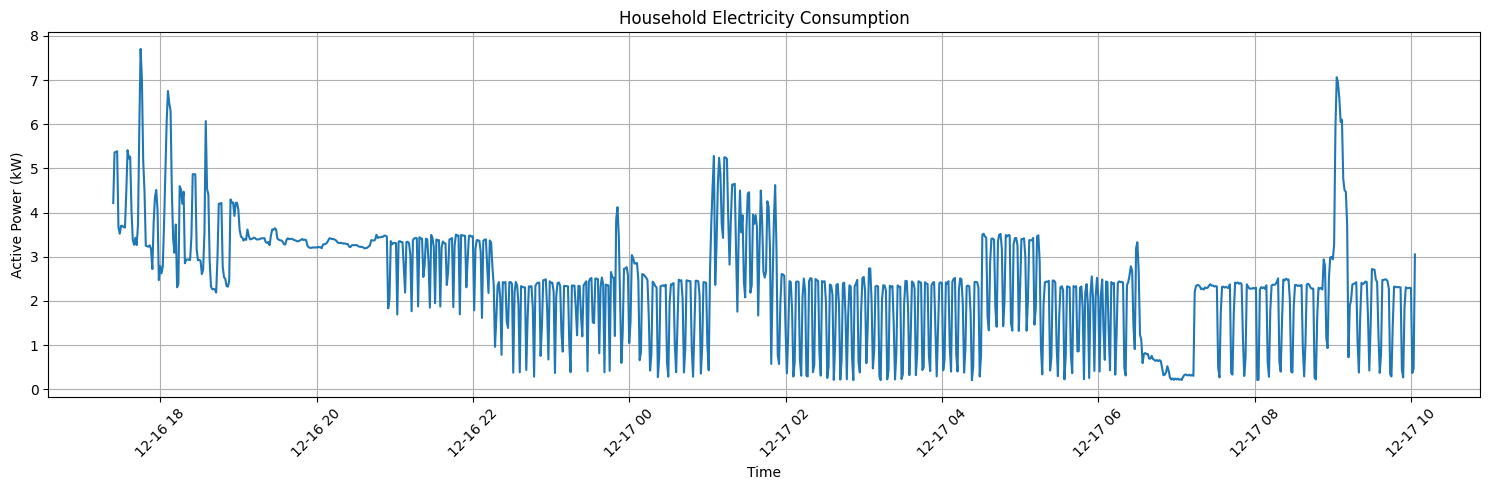

In [ ]:

plt.figure(figsize=(15, 5))

# Select first 1000 measurements
plt.plot(
    df.index[:1000],
    df["Global_active_power"].iloc[:1000]
)

plt.title("Household Electricity Consumption")
plt.xlabel("Time")
plt.ylabel("Active Power (kW)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

hourly_df = df.resample("h").mean()

print("Original dataset:", df.shape)
print("Hourly dataset:", hourly_df.shape)

hourly_df.head()


Original dataset: (2075259, 7)
Hourly dataset: (34589, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


In [ ]:

print("Hourly dataset information:")
print(hourly_df.info())

print("\nStatistical summary:")
display(hourly_df.describe())

print("\nFirst five records:")
display(hourly_df.head())


Hourly dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34589 entries, 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Freq: h
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Global_active_power    34589 non-null  float64
 1   Global_reactive_power  34589 non-null  float64
 2   Voltage                34589 non-null  float64
 3   Global_intensity       34589 non-null  float64
 4   Sub_metering_1         34589 non-null  float64
 5   Sub_metering_2         34589 non-null  float64
 6   Sub_metering_3         34589 non-null  float64
dtypes: float64(7)
memory usage: 2.1 MB
None

Statistical summary:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000
mean,1.090311,0.123647,240.832682,4.621615,1.109442,1.289185,6.442329
std,0.894323,0.067072,3.001576,3.743583,3.518391,4.168299,7.340881
min,0.124000,0.000000,225.834500,0.503333,0.000000,0.000000,0.000000
25%,0.342867,0.077933,239.178167,1.516667,0.000000,0.000000,0.650000
50%,0.803267,0.107133,240.974667,3.423333,0.000000,0.333333,1.650000
75%,1.578700,0.149500,242.689000,6.603333,0.000000,0.650000,14.083333
max,6.560533,0.774333,251.902000,28.383333,48.366667,46.433333,24.524501



First five records:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


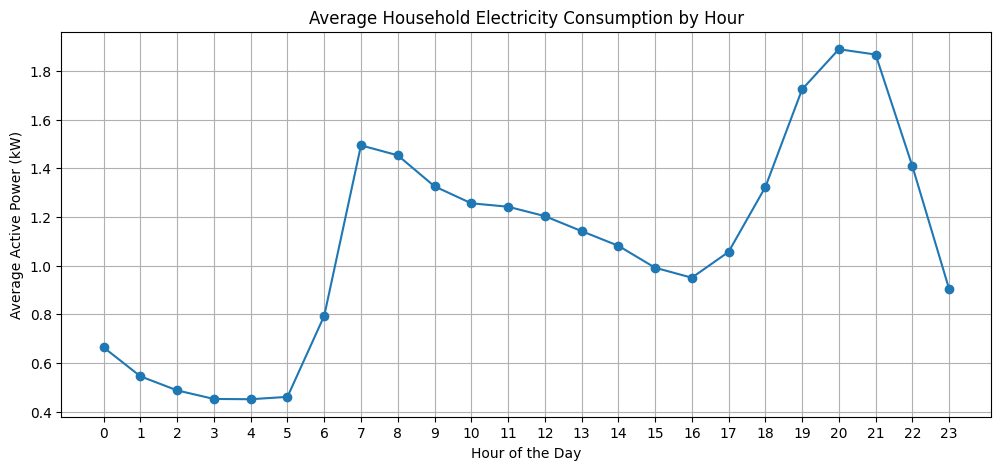

In [ ]:

hourly_df["Hour"] = hourly_df.index.hour

hourly_consumption = hourly_df.groupby("Hour")[
    "Global_active_power"
].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o"
)

plt.title("Average Household Electricity Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(True)
plt.show()


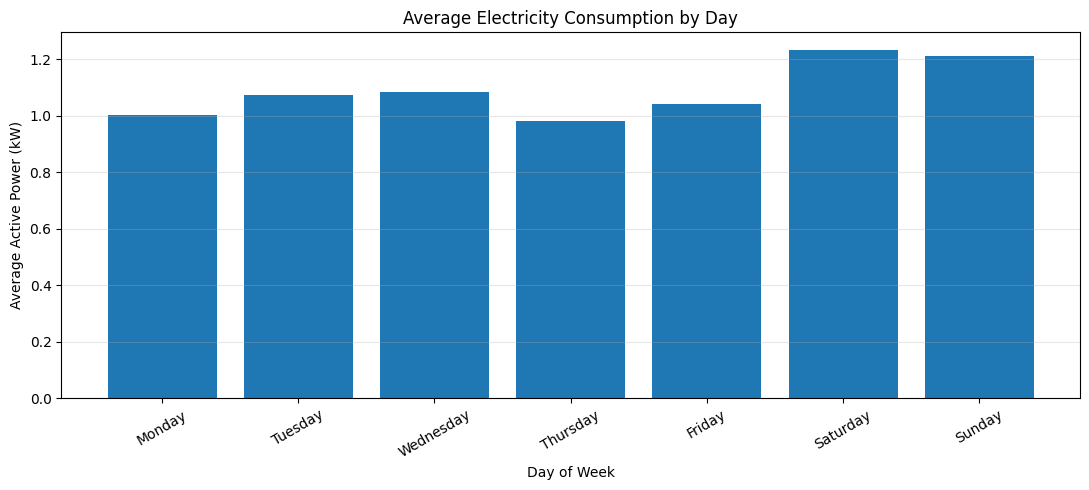

In [ ]:

hourly_df["Day_of_Week"] = hourly_df.index.dayofweek

# Calculate average consumption for each day
weekly_consumption = hourly_df.groupby("Day_of_Week")[
    "Global_active_power"
].mean()

days = ["Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(11, 5))

plt.bar(days, weekly_consumption.values)

plt.title("Average Electricity Consumption by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Active Power (kW)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


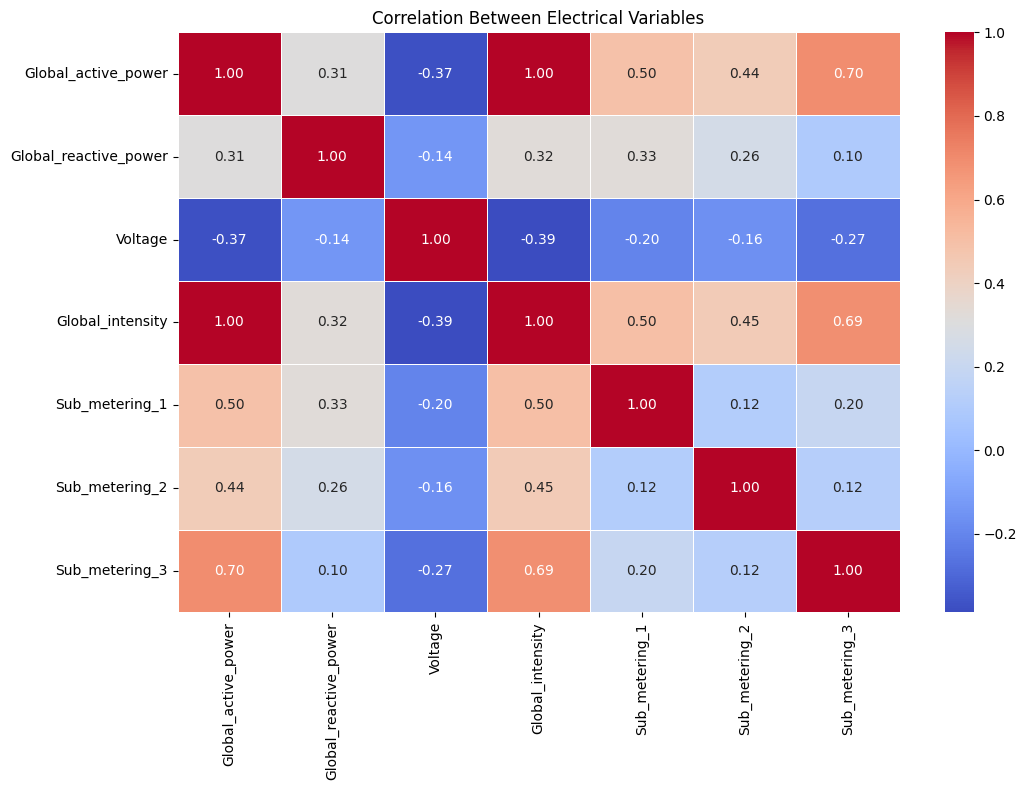

In [ ]:

correlation = hourly_df[
    [
        "Global_active_power",
        "Global_reactive_power",
        "Voltage",
        "Global_intensity",
        "Sub_metering_1",
        "Sub_metering_2",
        "Sub_metering_3"
    ]
].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Electrical Variables")
plt.tight_layout()
plt.show()


In [ ]:

hourly_df["Hour"] = hourly_df.index.hour

peak_hours = hourly_df.groupby("Hour")[
    "Global_active_power"
].mean().sort_values(ascending=False)

print("Top 5 electricity consumption hours:")
display(peak_hours.head(5))

print("\nLowest 5 electricity consumption hours:")
display(peak_hours.tail(5))


Top 5 electricity consumption hours:


,Global_active_power
Hour,
20,1.889776
21,1.867966
19,1.724749
7,1.494386
8,1.453509



Lowest 5 electricity consumption hours:


,Global_active_power
Hour,
1,0.544698
2,0.486809
5,0.460220
3,0.451589
4,0.450522


In [ ]:

# Create a separate feature dataset
model_df = hourly_df.copy()

# Current electricity consumption
model_df["Current_Load"] = model_df["Global_active_power"]

# Previous consumption
model_df["Load_Lag_1"] = model_df["Global_active_power"].shift(1)
model_df["Load_Lag_2"] = model_df["Global_active_power"].shift(2)
model_df["Load_Lag_3"] = model_df["Global_active_power"].shift(3)

# Same hour yesterday
model_df["Load_Lag_24"] = model_df["Global_active_power"].shift(24)

# Same hour last week
model_df["Load_Lag_168"] = model_df["Global_active_power"].shift(168)

print("Lag features created!")
display(model_df.head(10))


Lag features created!


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Current_Load,Load_Lag_1,Load_Lag_2,Load_Lag_3,Load_Lag_24,Load_Lag_168
Datetime,,,,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,4.222889,NaN,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,3.632200,4.222889,NaN,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,3.400233,3.632200,4.222889,NaN,NaN,NaN
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,3.268567,3.400233,3.632200,4.222889,NaN,NaN
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,3.056467,3.268567,3.400233,3.632200,NaN,NaN
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,0.133333,4.433333,22,5,2.200133,3.056467,3.268567,3.400233,NaN,NaN
2006-12-16 23:00:00,2.061600,0.071433,240.619667,8.896667,0.0,0.083333,0.000000,23,5,2.061600,2.200133,3.056467,3.268567,NaN,NaN
2006-12-17 00:00:00,1.882467,0.102433,240.961833,8.126667,0.0,0.466667,0.000000,0,6,1.882467,2.061600,2.200133,3.056467,NaN,NaN
2006-12-17 01:00:00,3.349400,0.136933,240.448333,14.246667,0.0,25.233333,0.000000,1,6,3.349400,1.882467,2.061600,2.200133,NaN,NaN


In [ ]:

# Rolling average features
model_df["Rolling_Mean_3"] = (
    model_df["Global_active_power"].rolling(window=3).mean()
)

model_df["Rolling_Mean_24"] = (
    model_df["Global_active_power"].rolling(window=24).mean()
)

model_df["Rolling_Mean_168"] = (
    model_df["Global_active_power"].rolling(window=168).mean()
)

# Rolling standard deviation
model_df["Rolling_Std_24"] = (
    model_df["Global_active_power"].rolling(window=24).std()
)

print("Rolling features created!")
display(model_df.head(10))


Rolling features created!


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Current_Load,Load_Lag_1,Load_Lag_2,Load_Lag_3,Load_Lag_24,Load_Lag_168,Rolling_Mean_3,Rolling_Mean_24,Rolling_Mean_168,Rolling_Std_24
Datetime,,,,,,,,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,4.222889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,3.632200,4.222889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,3.400233,3.632200,4.222889,NaN,NaN,NaN,3.751774,NaN,NaN,NaN
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,3.268567,3.400233,3.632200,4.222889,NaN,NaN,3.433667,NaN,NaN,NaN
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,3.056467,3.268567,3.400233,3.632200,NaN,NaN,3.241756,NaN,NaN,NaN
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,0.133333,4.433333,22,5,2.200133,3.056467,3.268567,3.400233,NaN,NaN,2.841722,NaN,NaN,NaN
2006-12-16 23:00:00,2.061600,0.071433,240.619667,8.896667,0.0,0.083333,0.000000,23,5,2.061600,2.200133,3.056467,3.268567,NaN,NaN,2.439400,NaN,NaN,NaN
2006-12-17 00:00:00,1.882467,0.102433,240.961833,8.126667,0.0,0.466667,0.000000,0,6,1.882467,2.061600,2.200133,3.056467,NaN,NaN,2.048067,NaN,NaN,NaN
2006-12-17 01:00:00,3.349400,0.136933,240.448333,14.246667,0.0,25.233333,0.000000,1,6,3.349400,1.882467,2.061600,2.200133,NaN,NaN,2.431156,NaN,NaN,NaN


In [ ]:

# Forecasting the next hour
forecast_time = model_df.index + pd.Timedelta(hours=1)

# Extract time information
model_df["Hour"] = forecast_time.hour
model_df["Day_of_Week"] = forecast_time.dayofweek
model_df["Month"] = forecast_time.month

# Cyclical encoding
model_df["Hour_Sin"] = np.sin(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Hour_Cos"] = np.cos(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Day_Sin"] = np.sin(
    2 * np.pi * model_df["Day_of_Week"] / 7
)

model_df["Day_Cos"] = np.cos(
    2 * np.pi * model_df["Day_of_Week"] / 7
)

# Weekend indicator
model_df["Is_Weekend"] = (
    model_df["Day_of_Week"] >= 5
).astype(int)

print("Cyclical and calendar features created!")
display(model_df.head())


Cyclical and calendar features created!


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Current_Load,...,Rolling_Mean_3,Rolling_Mean_24,Rolling_Mean_168,Rolling_Std_24,Month,Hour_Sin,Hour_Cos,Day_Sin,Day_Cos,Is_Weekend
Datetime,,,,,,,,,,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,18,5,4.222889,...,NaN,NaN,NaN,NaN,12,-1.000000,-1.836970e-16,-0.974928,-0.222521,1
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,19,5,3.632200,...,NaN,NaN,NaN,NaN,12,-0.965926,2.588190e-01,-0.974928,-0.222521,1
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,20,5,3.400233,...,3.751774,NaN,NaN,NaN,12,-0.866025,5.000000e-01,-0.974928,-0.222521,1
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,21,5,3.268567,...,3.433667,NaN,NaN,NaN,12,-0.707107,7.071068e-01,-0.974928,-0.222521,1
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,22,5,3.056467,...,3.241756,NaN,NaN,NaN,12,-0.500000,8.660254e-01,-0.974928,-0.222521,1


In [ ]:

# Target: electricity consumption in the next hour
model_df["Target_Load"] = (
    model_df["Global_active_power"].shift(-1)
)

print("Prediction target created!")

display(
    model_df[
        ["Global_active_power", "Target_Load"]
    ].head(10)
)


Prediction target created!


,Global_active_power,Target_Load
Datetime,,
2006-12-16 17:00:00,4.222889,3.632200
2006-12-16 18:00:00,3.632200,3.400233
2006-12-16 19:00:00,3.400233,3.268567
2006-12-16 20:00:00,3.268567,3.056467
2006-12-16 21:00:00,3.056467,2.200133
2006-12-16 22:00:00,2.200133,2.061600
2006-12-16 23:00:00,2.061600,1.882467
2006-12-17 00:00:00,1.882467,3.349400
2006-12-17 01:00:00,3.349400,1.587267


In [ ]:

# Remove rows with missing values in required features
model_df = model_df.dropna().copy()

print("Final modelling dataset shape:", model_df.shape)

print("\nRemaining missing values:")
print(model_df.isnull().sum().sum())

display(model_df.head())


Final modelling dataset shape: (34420, 26)

Remaining missing values:
0


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Current_Load,...,Rolling_Mean_24,Rolling_Mean_168,Rolling_Std_24,Month,Hour_Sin,Hour_Cos,Day_Sin,Day_Cos,Is_Weekend,Target_Load
Datetime,,,,,,,,,,,,,,,,,,,,,
2006-12-23 17:00:00,5.452533,0.215967,233.644167,23.360000,16.183333,0.666667,16.750000,18,5,5.452533,...,3.099713,1.771207,1.066674,12,-1.000000,-1.836970e-16,-0.974928,-0.222521,1,3.879400
2006-12-23 18:00:00,3.879400,0.099767,238.000500,16.363333,0.000000,0.016667,17.350000,19,5,3.879400,...,3.149397,1.772679,1.074356,12,-0.965926,2.588190e-01,-0.974928,-0.222521,1,4.117833
2006-12-23 19:00:00,4.117833,0.205333,238.729333,17.300000,0.000000,0.600000,17.466667,20,5,4.117833,...,3.156883,1.776950,1.080699,12,-0.866025,5.000000e-01,-0.974928,-0.222521,1,4.181400
2006-12-23 20:00:00,4.181400,0.124767,238.518833,17.596667,0.000000,0.350000,17.416667,21,5,4.181400,...,3.183772,1.782384,1.098426,12,-0.707107,7.071068e-01,-0.974928,-0.222521,1,3.288433
2006-12-23 21:00:00,3.288433,0.235767,238.594667,13.893333,0.000000,0.216667,5.666667,22,5,3.288433,...,3.131263,1.783764,1.059784,12,-0.500000,8.660254e-01,-0.974928,-0.222521,1,4.327933


In [ ]:
print("Final shape:", model_df.shape)
print("\nFeatures:")
print(model_df.columns.tolist())

Final shape: (34420, 26)

Features:
['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hour', 'Day_of_Week', 'Current_Load', 'Load_Lag_1', 'Load_Lag_2', 'Load_Lag_3', 'Load_Lag_24', 'Load_Lag_168', 'Rolling_Mean_3', 'Rolling_Mean_24', 'Rolling_Mean_168', 'Rolling_Std_24', 'Month', 'Hour_Sin', 'Hour_Cos', 'Day_Sin', 'Day_Cos', 'Is_Weekend', 'Target_Load']


In [ ]:
# Add cyclical month features
model_df["Month_Sin"] = np.sin(2 * np.pi * model_df["Month"] / 12)
model_df["Month_Cos"] = np.cos(2 * np.pi * model_df["Month"] / 12)

# Select input features
feature_cols = [
    "Current_Load",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
    "Load_Lag_1",
    "Load_Lag_2",
    "Load_Lag_3",
    "Load_Lag_24",
    "Load_Lag_168",
    "Rolling_Mean_3",
    "Rolling_Mean_24",
    "Rolling_Mean_168",
    "Rolling_Std_24",
    "Hour_Sin",
    "Hour_Cos",
    "Day_Sin",
    "Day_Cos",
    "Is_Weekend",
    "Month_Sin",
    "Month_Cos"
]

X = model_df[feature_cols]
y = model_df["Target_Load"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (34420, 23)
Target: (34420,)


In [ ]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (27536, 23)
Testing: (6884, 23)


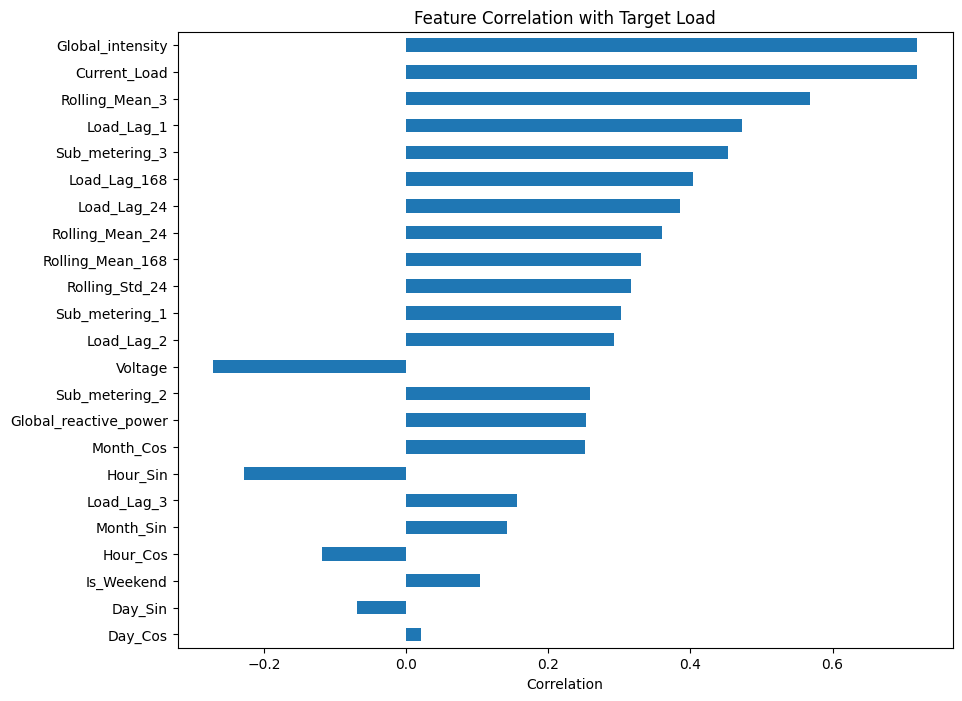

Global_intensity         0.719225
Current_Load             0.719025
Rolling_Mean_3           0.568288
Load_Lag_1               0.472463
Sub_metering_3           0.452664
Load_Lag_168             0.404160
Load_Lag_24              0.385795
Rolling_Mean_24          0.359959
Rolling_Mean_168         0.330082
Rolling_Std_24           0.316231
Sub_metering_1           0.302331
Load_Lag_2               0.292942
Voltage                 -0.271756
Sub_metering_2           0.258671
Global_reactive_power    0.252933
Month_Cos                0.251889
Hour_Sin                -0.227854
Load_Lag_3               0.156346
Month_Sin                0.142070
Hour_Cos                -0.118576
Is_Weekend               0.103545
Day_Sin                 -0.068791
Day_Cos                  0.020497
Name: Target_Load, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

train_corr = X_train.copy()
train_corr["Target_Load"] = y_train

target_corr = train_corr.corr()["Target_Load"].drop("Target_Load")

target_corr = target_corr.sort_values(
    key=abs,
    ascending=False
)

plt.figure(figsize=(10, 8))
target_corr.plot(kind="barh")
plt.title("Feature Correlation with Target Load")
plt.xlabel("Correlation")
plt.gca().invert_yaxis()
plt.show()

print(target_corr)

In [ ]:
top_features = target_corr.abs().sort_values(
    ascending=False
).head(12).index.tolist()

print("Selected features:")
print(top_features)

X_train_selected = X_train[top_features]
X_test_selected = X_test[top_features]

Selected features:
['Global_intensity', 'Current_Load', 'Rolling_Mean_3', 'Load_Lag_1', 'Sub_metering_3', 'Load_Lag_168', 'Load_Lag_24', 'Rolling_Mean_24', 'Rolling_Mean_168', 'Rolling_Std_24', 'Sub_metering_1', 'Load_Lag_2']


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA components:", X_train_pca.shape[1])

print(
    "Explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Original features: 23
PCA components: 16
Explained variance: 96.3 %


All six models defined successfully!
Training Linear Regression...
Linear Regression completed in 0.03 seconds
Training Ridge Regression...
Ridge Regression completed in 0.12 seconds
Training Lasso Regression...
Lasso Regression completed in 0.70 seconds
Training Decision Tree...
Decision Tree completed in 1.13 seconds
Training SVR...
SVR completed in 720.61 seconds
Training MLP Neural Network...
MLP Neural Network completed in 7.87 seconds

All models trained!


,Model,MAE,RMSE,R2 Score,Training Time (s)
5,MLP Neural Network,0.337806,0.479526,0.566252,7.873582
4,SVR,0.328895,0.486730,0.553121,720.610851
2,Lasso Regression,0.368421,0.515881,0.497988,0.702153
1,Ridge Regression,0.368958,0.516265,0.497241,0.122074
0,Linear Regression,0.368967,0.516269,0.497233,0.031448
3,Decision Tree,0.401964,0.613824,0.289275,1.125764


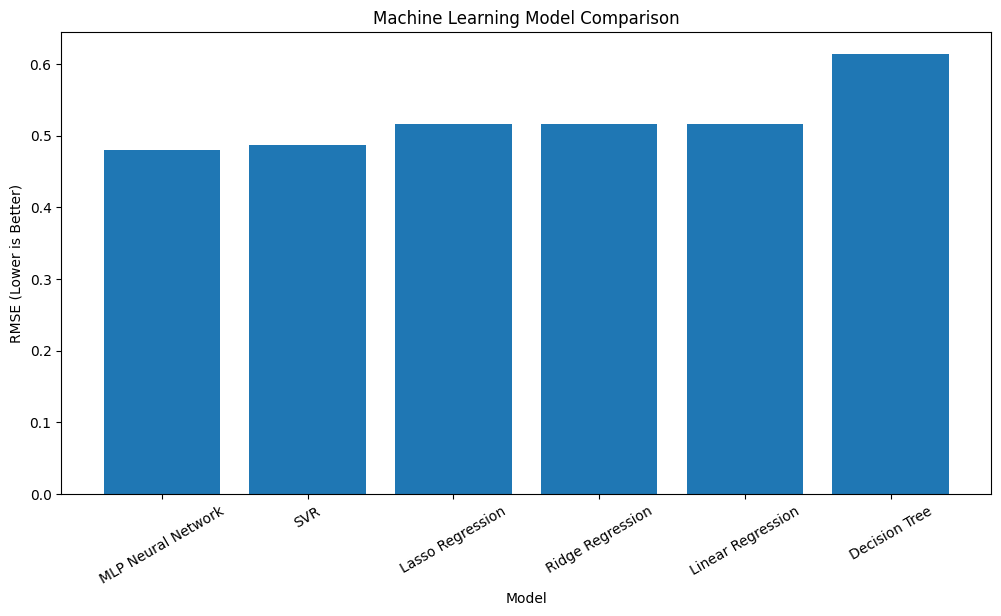

BASELINE MODEL RESULTS
MAE: 0.38085627716023585
RMSE: 0.5894249252313656
R2 Score: 0.3446531102088919


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd
import time
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(alpha=0.001),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=10,
        random_state=42
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    ),

    "MLP Neural Network": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=200,
        early_stopping=True,
        random_state=42
    )
}

print("All six models defined successfully!")
trained_models = {}
training_times = {}

for name, model in models.items():

    print(f"Training {name}...")

    start_time = time.time()

    if name == "Decision Tree":
        model.fit(X_train, y_train)
    else:
        model.fit(X_train_scaled, y_train)

    end_time = time.time()

    trained_models[name] = model
    training_times[name] = end_time - start_time

    print(f"{name} completed in {end_time - start_time:.2f} seconds")

print("\nAll models trained!")
results = []

for name, model in trained_models.items():

    if name == "Decision Tree":
        predictions = model.predict(X_test)
    else:
        predictions = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Training Time (s)": training_times[name]
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

display(results_df)
plt.figure(figsize=(12, 6))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=30)

plt.show()
baseline_predictions = X_test["Current_Load"].values

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

In [ ]:
# Calculate baseline predictions
baseline_predictions = X_test["Current_Load"].values

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

# Add baseline to comparison table
baseline_row = pd.DataFrame([{
    "Model": "Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2 Score": baseline_r2,
    "Training Time (s)": 0
}])

comparison_df = pd.concat(
    [results_df, baseline_row],
    ignore_index=True
)

comparison_df = comparison_df.sort_values("RMSE")

display(comparison_df)

,Model,MAE,RMSE,R2 Score,Training Time (s)
0,MLP Neural Network,0.337806,0.479526,0.566252,7.873582
1,SVR,0.328895,0.486730,0.553121,720.610851
2,Lasso Regression,0.368421,0.515881,0.497988,0.702153
3,Ridge Regression,0.368958,0.516265,0.497241,0.122074
4,Linear Regression,0.368967,0.516269,0.497233,0.031448
6,Baseline,0.380856,0.589425,0.344653,0.000000
5,Decision Tree,0.401964,0.613824,0.289275,1.125764


In [ ]:
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: MLP Neural Network


In [ ]:
if best_model_name == "Decision Tree":
    best_predictions = best_model.predict(X_test)
else:
    best_predictions = best_model.predict(X_test_scaled)

print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(best_predictions[:10])

Actual values:
[0.28696667 0.29213333 0.3372     0.35716667 1.14293333 1.964
 2.06196667 1.93863333 2.6426     1.50286667]

Predicted values:
[0.40009074 0.34490938 0.33663101 0.3704378  0.51492318 1.56021024
 1.78543732 1.78565962 1.96112819 2.54661215]


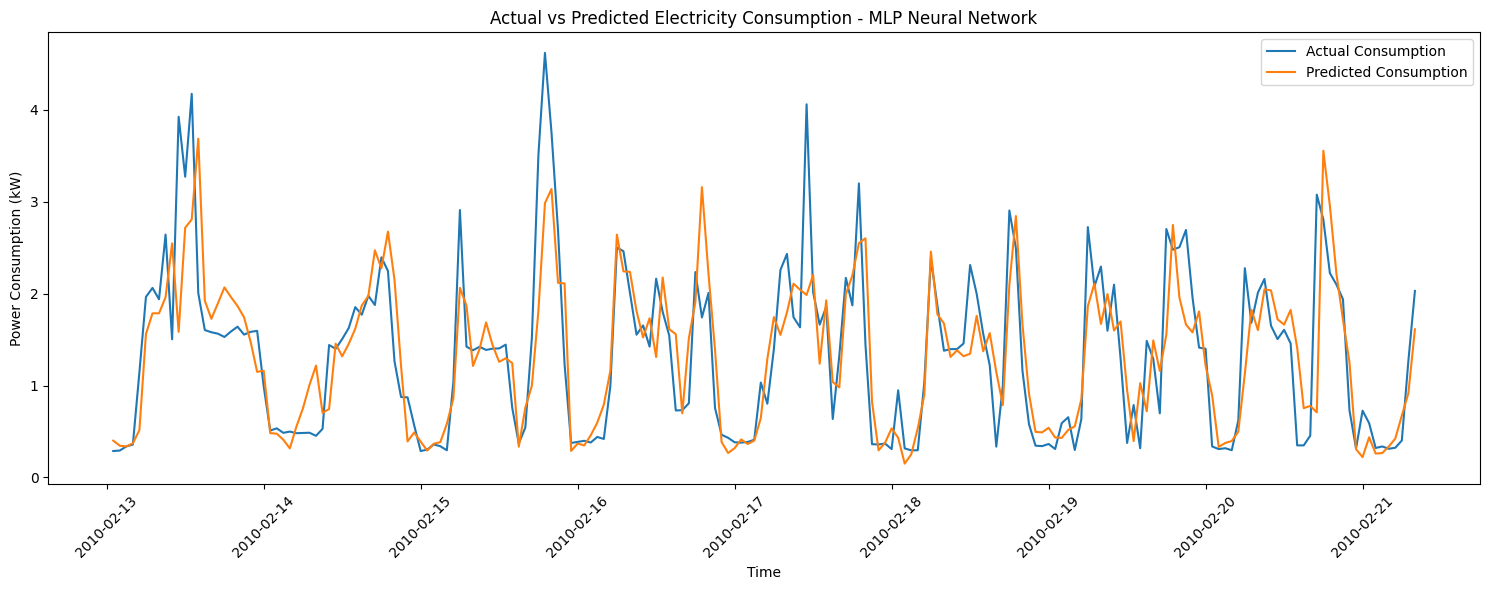

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index[:200],
    y_test.iloc[:200],
    label="Actual Consumption"
)

plt.plot(
    y_test.index[:200],
    best_predictions[:200],
    label="Predicted Consumption"
)

plt.title(f"Actual vs Predicted Electricity Consumption - {best_model_name}")
plt.xlabel("Time")
plt.ylabel("Power Consumption (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

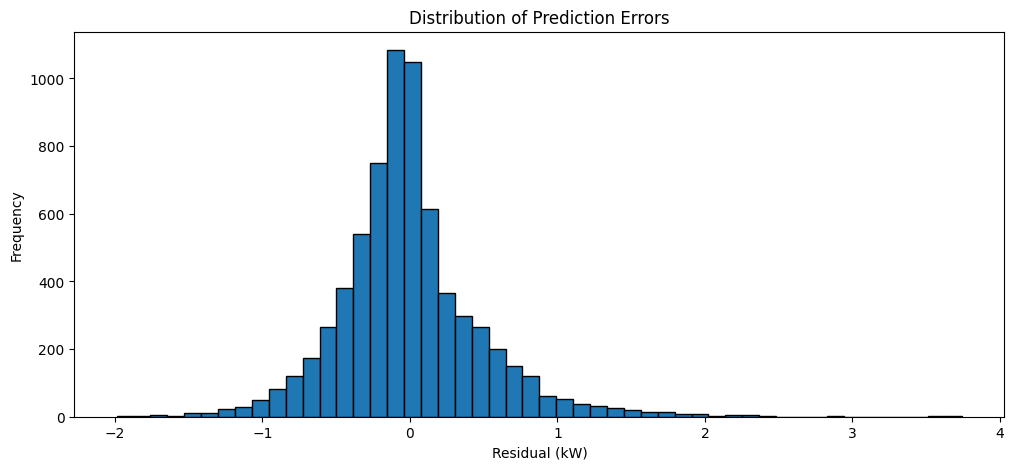

Mean residual: -0.009533045336314617
Residual standard deviation: 0.4794307923092454


In [ ]:
residuals = y_test.values - best_predictions

plt.figure(figsize=(12, 5))
plt.hist(residuals, bins=50, edgecolor="black")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual (kW)")
plt.ylabel("Frequency")
plt.show()

print("Mean residual:", np.mean(residuals))
print("Residual standard deviation:", np.std(residuals))

In [ ]:
# Calculate residuals on training data

if best_model_name == "Decision Tree":
    train_predictions = best_model.predict(X_train)
else:
    train_predictions = best_model.predict(X_train_scaled)

train_residuals = y_train.values - train_predictions

print("Training residual mean:", np.mean(train_residuals))
print("Training residual standard deviation:", np.std(train_residuals))

Training residual mean: -0.005258470876784785
Training residual standard deviation: 0.4989050525316134


In [ ]:
# Calculate 90% residual error threshold

error_threshold = np.quantile(
    np.abs(train_residuals),
    0.90
)

print("90% error threshold:", error_threshold)

90% error threshold: 0.8050387456199248


In [ ]:
lower_bound = best_predictions - error_threshold
upper_bound = best_predictions + error_threshold

prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": best_predictions,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound
}, index=y_test.index)

display(prediction_results.head(10))

,Actual,Predicted,Lower Bound,Upper Bound
Datetime,,,,
2010-02-13 01:00:00,0.286967,0.400091,-0.404948,1.205129
2010-02-13 02:00:00,0.292133,0.344909,-0.460129,1.149948
2010-02-13 03:00:00,0.337200,0.336631,-0.468408,1.141670
2010-02-13 04:00:00,0.357167,0.370438,-0.434601,1.175477
2010-02-13 05:00:00,1.142933,0.514923,-0.290116,1.319962
2010-02-13 06:00:00,1.964000,1.560210,0.755171,2.365249
2010-02-13 07:00:00,2.061967,1.785437,0.980399,2.590476
2010-02-13 08:00:00,1.938633,1.785660,0.980621,2.590698
2010-02-13 09:00:00,2.642600,1.961128,1.156089,2.766167


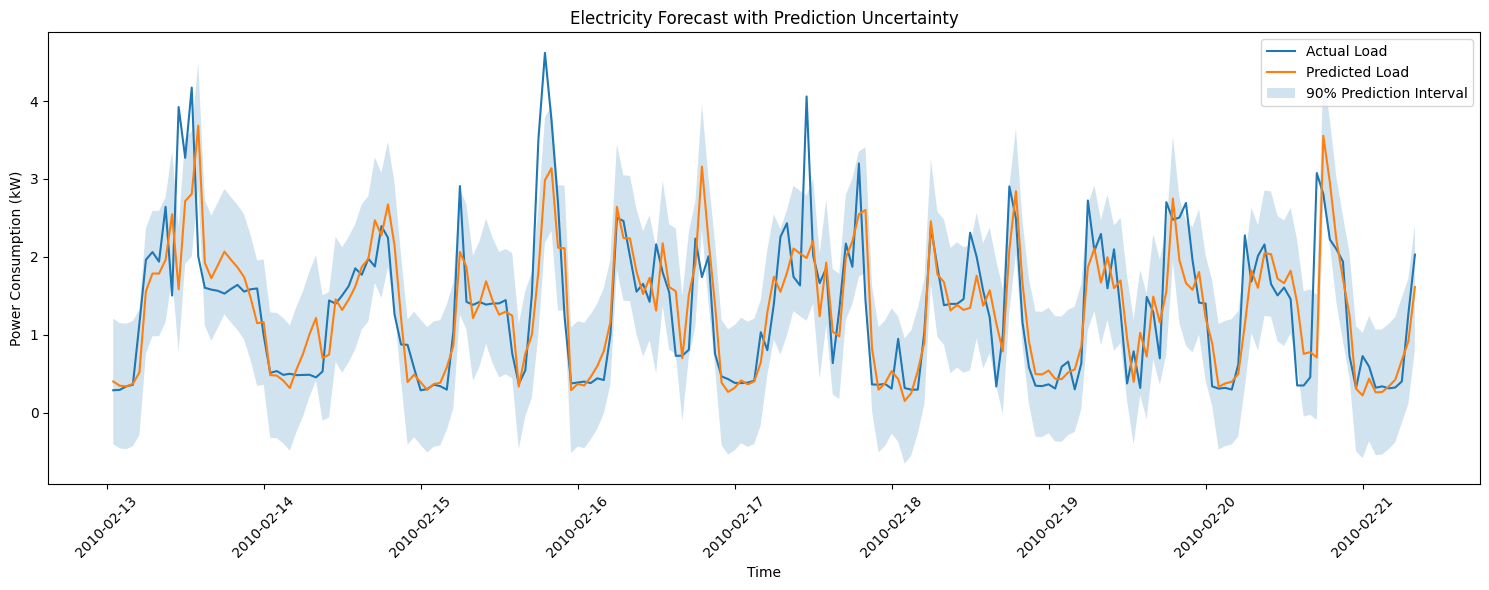

In [ ]:
plt.figure(figsize=(15, 6))

sample_size = 200

plt.plot(
    y_test.index[:sample_size],
    y_test.iloc[:sample_size],
    label="Actual Load"
)

plt.plot(
    y_test.index[:sample_size],
    best_predictions[:sample_size],
    label="Predicted Load"
)

plt.fill_between(
    y_test.index[:sample_size],
    lower_bound[:sample_size],
    upper_bound[:sample_size],
    alpha=0.2,
    label="90% Prediction Interval"
)

plt.title("Electricity Forecast with Prediction Uncertainty")
plt.xlabel("Time")
plt.ylabel("Power Consumption (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
coverage = np.mean(
    (y_test.values >= lower_bound) &
    (y_test.values <= upper_bound)
)

print("Prediction Interval Coverage:", round(coverage * 100, 2), "%")

Prediction Interval Coverage: 91.12 %


In [ ]:
import requests
import pandas as pd
import numpy as np

# Sceaux, France
latitude = 48.78
longitude = 2.29

# Match the household dataset's date range
start_date = hourly_df.index.min().strftime("%Y%m%d")
end_date = hourly_df.index.max().strftime("%Y%m%d")

# NASA POWER API
url = "https://power.larc.nasa.gov/api/temporal/hourly/point"

params = {
    "parameters": "ALLSKY_SFC_SW_DWN,T2M",
    "community": "RE",
    "longitude": longitude,
    "latitude": latitude,
    "start": start_date,
    "end": end_date,
    "format": "JSON",
    "time-standard": "UTC"
}

print("Downloading NASA solar and weather data...")

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

data = response.json()

print("Download successful!")

Download successful!


In [ ]:
import pandas as pd
import numpy as np

# Extract NASA parameters
parameters = data["properties"]["parameter"]

solar_weather_df = pd.DataFrame({
    "Solar_Irradiance": pd.Series(parameters["ALLSKY_SFC_SW_DWN"]),
    "Temperature_C": pd.Series(parameters["T2M"])
})

# Convert timestamps
solar_weather_df.index = pd.to_datetime(
    solar_weather_df.index,
    format="%Y%m%d%H",
    utc=True
)

# Convert UTC to French local time
solar_weather_df.index = (
    solar_weather_df.index
    .tz_convert("Europe/Paris")
    .tz_localize(None)
)

# Replace missing-value indicators
solar_weather_df = solar_weather_df.replace(-999, np.nan)

solar_weather_df = solar_weather_df.sort_index()

print("Dataset created successfully!")
display(solar_weather_df.head())

Dataset created successfully!


,Solar_Irradiance,Temperature_C
2006-12-16 01:00:00,0.0,4.75
2006-12-16 02:00:00,0.0,4.68
2006-12-16 03:00:00,0.0,4.86
2006-12-16 04:00:00,0.0,4.96
2006-12-16 05:00:00,0.0,4.88


In [ ]:
print("Shape:", solar_weather_df.shape)
display(solar_weather_df.describe())

Shape: (34608, 2)


,Solar_Irradiance,Temperature_C
count,34608.000000,34608.000000
mean,137.715900,10.585182
std,206.365855,7.461169
min,0.000000,-12.330000
25%,0.000000,5.110000
50%,7.050000,10.570000
75%,219.180000,16.020000
max,935.150000,33.600000


In [ ]:
print("Dataset shape:", solar_weather_df.shape)

print("\nDataset information:")
solar_weather_df.info()

print("\nMissing values:")
print(solar_weather_df.isnull().sum())

print("\nStatistical summary:")
display(solar_weather_df.describe())

print("\nFirst 10 records:")
display(solar_weather_df.head(10))

Dataset shape: (34608, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34608 entries, 2006-12-16 01:00:00 to 2010-11-27 00:00:00
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Solar_Irradiance  34608 non-null  float64
 1   Temperature_C     34608 non-null  float64
dtypes: float64(2)
memory usage: 811.1 KB

Missing values:
Solar_Irradiance    0
Temperature_C       0
dtype: int64

Statistical summary:


,Solar_Irradiance,Temperature_C
count,34608.000000,34608.000000
mean,137.715900,10.585182
std,206.365855,7.461169
min,0.000000,-12.330000
25%,0.000000,5.110000
50%,7.050000,10.570000
75%,219.180000,16.020000
max,935.150000,33.600000



First 10 records:


,Solar_Irradiance,Temperature_C
2006-12-16 01:00:00,0.0,4.75
2006-12-16 02:00:00,0.0,4.68
2006-12-16 03:00:00,0.0,4.86
2006-12-16 04:00:00,0.0,4.96
2006-12-16 05:00:00,0.0,4.88
2006-12-16 06:00:00,0.0,4.72
2006-12-16 07:00:00,0.0,4.69
2006-12-16 08:00:00,0.0,4.77
2006-12-16 09:00:00,31.3,4.98
2006-12-16 10:00:00,65.0,5.34


In [ ]:
print(solar_weather_df["Solar_Irradiance"].head(10))

2006-12-16 01:00:00     0.0
2006-12-16 02:00:00     0.0
2006-12-16 03:00:00     0.0
2006-12-16 04:00:00     0.0
2006-12-16 05:00:00     0.0
2006-12-16 06:00:00     0.0
2006-12-16 07:00:00     0.0
2006-12-16 08:00:00     0.0
2006-12-16 09:00:00    31.3
2006-12-16 10:00:00    65.0
Name: Solar_Irradiance, dtype: float64


In [ ]:
print(data.get("parameters", {}).get("ALLSKY_SFC_SW_DWN"))

{'units': 'Wh/m^2', 'longname': 'All Sky Surface Shortwave Downward Irradiance'}


In [ ]:
solar_weather_df["Solar_Energy_kWh_m2"] = (
    solar_weather_df["Solar_Irradiance"] / 1000
)

display(solar_weather_df.head(10))

,Solar_Irradiance,Temperature_C,Solar_Energy_kWh_m2
2006-12-16 01:00:00,0.0,4.75,0.0000
2006-12-16 02:00:00,0.0,4.68,0.0000
2006-12-16 03:00:00,0.0,4.86,0.0000
2006-12-16 04:00:00,0.0,4.96,0.0000
2006-12-16 05:00:00,0.0,4.88,0.0000
2006-12-16 06:00:00,0.0,4.72,0.0000
2006-12-16 07:00:00,0.0,4.69,0.0000
2006-12-16 08:00:00,0.0,4.77,0.0000
2006-12-16 09:00:00,31.3,4.98,0.0313
2006-12-16 10:00:00,65.0,5.34,0.0650


In [ ]:
display(
    solar_weather_df[
        ["Solar_Irradiance", "Solar_Energy_kWh_m2", "Temperature_C"]
    ].describe()
)

,Solar_Irradiance,Solar_Energy_kWh_m2,Temperature_C
count,34608.000000,34608.000000,34608.000000
mean,137.715900,0.137716,10.585182
std,206.365855,0.206366,7.461169
min,0.000000,0.000000,-12.330000
25%,0.000000,0.000000,5.110000
50%,7.050000,0.007050,10.570000
75%,219.180000,0.219180,16.020000
max,935.150000,0.935150,33.600000


In [ ]:
# Combine both datasets using their timestamps
combined_df = hourly_df.join(
    solar_weather_df,
    how="inner"
)

print("Combined dataset shape:", combined_df.shape)

print("\nDataset columns:")
print(combined_df.columns.tolist())

print("\nFirst 10 records:")
display(combined_df.head(10))

Combined dataset shape: (34589, 12)

Dataset columns:
['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hour', 'Day_of_Week', 'Solar_Irradiance', 'Temperature_C', 'Solar_Energy_kWh_m2']

First 10 records:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Solar_Irradiance,Temperature_C,Solar_Energy_kWh_m2
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,0.0,5.14,0.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,0.0,3.96,0.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,0.0,2.97,0.0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,0.0,1.99,0.0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,0.0,0.98,0.0
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,0.133333,4.433333,22,5,0.0,0.51,0.0
2006-12-16 23:00:00,2.061600,0.071433,240.619667,8.896667,0.0,0.083333,0.000000,23,5,0.0,0.33,0.0
2006-12-17 00:00:00,1.882467,0.102433,240.961833,8.126667,0.0,0.466667,0.000000,0,6,0.0,-0.08,0.0
2006-12-17 01:00:00,3.349400,0.136933,240.448333,14.246667,0.0,25.233333,0.000000,1,6,0.0,-0.45,0.0
2006-12-17 02:00:00,1.587267,0.078233,245.818667,6.870000,0.0,0.566667,0.000000,2,6,0.0,-0.33,0.0


In [ ]:
print("Date range:")
print("Start:", combined_df.index.min())
print("End:", combined_df.index.max())

print("\nMissing values:")
print(combined_df.isnull().sum())

print("\nStatistical summary:")
display(combined_df.describe())

Date range:
Start: 2006-12-16 17:00:00
End: 2010-11-26 21:00:00

Missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Hour                     0
Day_of_Week              0
Solar_Irradiance         0
Temperature_C            0
Solar_Energy_kWh_m2      0
dtype: int64

Statistical summary:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Solar_Irradiance,Temperature_C,Solar_Energy_kWh_m2
count,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000
mean,1.090255,0.123653,240.832926,4.621382,1.109632,1.289209,6.442066,11.501084,2.998959,137.779418,10.588670,0.137779
std,0.894312,0.067073,3.001825,3.743549,3.518647,4.168294,7.340630,6.922394,2.000072,206.403329,7.461449,0.206403
min,0.124000,0.000000,225.834500,0.503333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-12.330000,0.000000
25%,0.342867,0.077933,239.178167,1.516667,0.000000,0.000000,0.650000,6.000000,1.000000,0.000000,5.110000,0.000000
50%,0.803216,0.107133,240.974667,3.423333,0.000000,0.333333,1.650000,12.000000,3.000000,7.070000,10.570000,0.007070
75%,1.578700,0.149500,242.689000,6.603333,0.000000,0.650000,14.083333,18.000000,5.000000,219.270000,16.020000,0.219270
max,6.560533,0.774333,251.902000,28.383333,48.366667,46.433333,24.524501,23.000000,6.000000,935.150000,33.600000,0.935150


In [ ]:
SOLAR_CAPACITY_KWP = 3.0
PERFORMANCE_RATIO = 0.80

combined_df["Solar_Generation_kWh"] = (
    combined_df["Solar_Energy_kWh_m2"]
    * SOLAR_CAPACITY_KWP
    * PERFORMANCE_RATIO
)

print("Solar generation calculated!")
display(
    combined_df[
        ["Global_active_power", "Solar_Generation_kWh"]
    ].head(10)
)

Solar generation calculated!


,Global_active_power,Solar_Generation_kWh
2006-12-16 17:00:00,4.222889,0.0
2006-12-16 18:00:00,3.632200,0.0
2006-12-16 19:00:00,3.400233,0.0
2006-12-16 20:00:00,3.268567,0.0
2006-12-16 21:00:00,3.056467,0.0
2006-12-16 22:00:00,2.200133,0.0
2006-12-16 23:00:00,2.061600,0.0
2006-12-17 00:00:00,1.882467,0.0
2006-12-17 01:00:00,3.349400,0.0
2006-12-17 02:00:00,1.587267,0.0


In [ ]:
combined_df["Net_Grid_Load"] = (
    combined_df["Global_active_power"]
    - combined_df["Solar_Generation_kWh"]
)

display(
    combined_df[
        ["Global_active_power",
         "Solar_Generation_kWh",
         "Net_Grid_Load"]
    ].head(10)
)

,Global_active_power,Solar_Generation_kWh,Net_Grid_Load
2006-12-16 17:00:00,4.222889,0.0,4.222889
2006-12-16 18:00:00,3.632200,0.0,3.632200
2006-12-16 19:00:00,3.400233,0.0,3.400233
2006-12-16 20:00:00,3.268567,0.0,3.268567
2006-12-16 21:00:00,3.056467,0.0,3.056467
2006-12-16 22:00:00,2.200133,0.0,2.200133
2006-12-16 23:00:00,2.061600,0.0,2.061600
2006-12-17 00:00:00,1.882467,0.0,1.882467
2006-12-17 01:00:00,3.349400,0.0,3.349400
2006-12-17 02:00:00,1.587267,0.0,1.587267


In [ ]:
# Display records with the highest solar generation
display(
    combined_df.nlargest(
        10, "Solar_Generation_kWh"
    )[
        [
            "Global_active_power",
            "Solar_Irradiance",
            "Solar_Generation_kWh",
            "Net_Grid_Load"
        ]
    ]
)

,Global_active_power,Solar_Irradiance,Solar_Generation_kWh,Net_Grid_Load
2009-05-30 13:00:00,1.692200,935.15,2.244360,-0.552160
2009-05-22 13:00:00,0.537767,929.05,2.229720,-1.691953
2009-05-30 14:00:00,1.296767,922.45,2.213880,-0.917113
2010-05-20 13:00:00,0.874433,921.45,2.211480,-1.337047
2009-05-22 14:00:00,0.506267,917.75,2.202600,-1.696333
2010-07-04 13:00:00,0.388600,916.50,2.199600,-1.811000
2010-05-24 13:00:00,0.477167,912.10,2.189040,-1.711873
2010-07-04 14:00:00,0.371600,911.15,2.186760,-1.815160
2008-07-01 13:00:00,0.494100,911.05,2.186520,-1.692420
2009-06-02 13:00:00,0.283933,910.92,2.186208,-1.902275


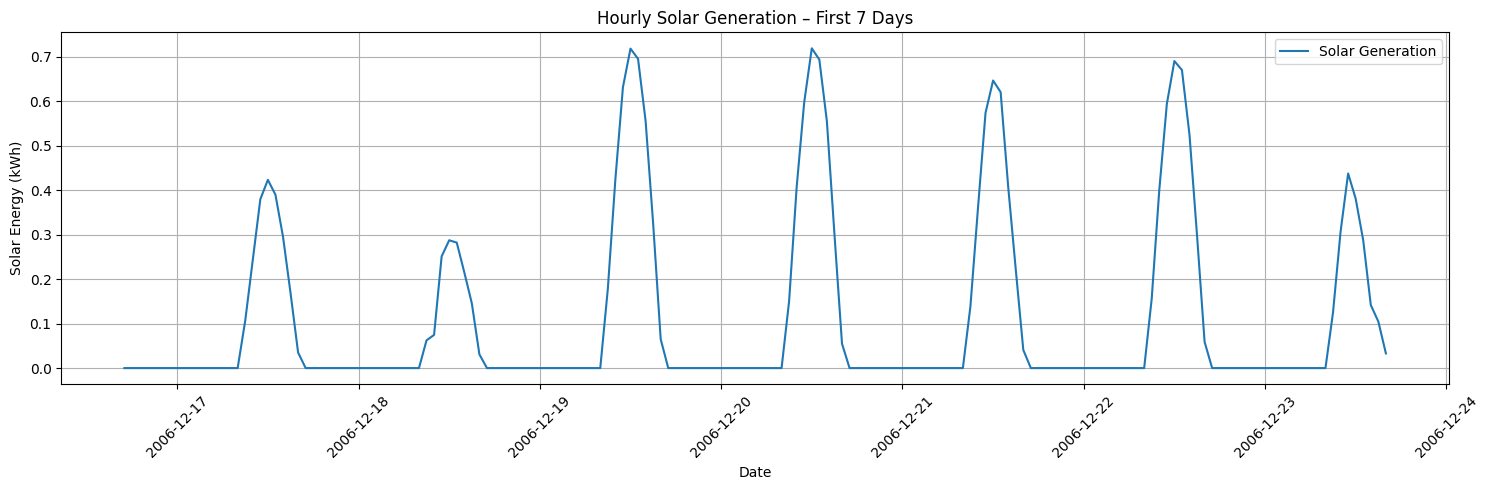

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    combined_df.index[:168],
    combined_df["Solar_Generation_kWh"].iloc[:168],
    label="Solar Generation"
)

plt.title("Hourly Solar Generation – First 7 Days")
plt.xlabel("Date")
plt.ylabel("Solar Energy (kWh)")
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Create forecasting dataset
forecast_df = combined_df.copy()

# Target: next hour's net grid load
forecast_df["Target_Net_Grid_Load"] = (
    forecast_df["Net_Grid_Load"].shift(-1)
)

# Remove rows with missing target
forecast_df = forecast_df.dropna()

print("Forecasting dataset shape:", forecast_df.shape)

display(forecast_df.head())

Forecasting dataset shape: (34588, 15)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Solar_Irradiance,Temperature_C,Solar_Energy_kWh_m2,Solar_Generation_kWh,Net_Grid_Load,Target_Net_Grid_Load
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,0.0,5.14,0.0,0.0,4.222889,3.632200
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,0.0,3.96,0.0,0.0,3.632200,3.400233
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,0.0,2.97,0.0,0.0,3.400233,3.268567
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,0.0,1.99,0.0,0.0,3.268567,3.056467
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,0.0,0.98,0.0,0.0,3.056467,2.200133


In [ ]:
forecast_df["Hour"] = forecast_df.index.hour
forecast_df["Day_of_Week"] = forecast_df.index.dayofweek
forecast_df["Month"] = forecast_df.index.month

# Cyclical encoding
forecast_df["Hour_Sin"] = np.sin(
    2 * np.pi * forecast_df["Hour"] / 24
)

forecast_df["Hour_Cos"] = np.cos(
    2 * np.pi * forecast_df["Hour"] / 24
)

forecast_df["Day_Sin"] = np.sin(
    2 * np.pi * forecast_df["Day_of_Week"] / 7
)

forecast_df["Day_Cos"] = np.cos(
    2 * np.pi * forecast_df["Day_of_Week"] / 7
)

print("Time features created!")
display(forecast_df.head())

Time features created!


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day_of_Week,Solar_Irradiance,Temperature_C,Solar_Energy_kWh_m2,Solar_Generation_kWh,Net_Grid_Load,Target_Net_Grid_Load,Month,Hour_Sin,Hour_Cos,Day_Sin,Day_Cos
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,0.0,5.14,0.0,0.0,4.222889,3.632200,12,-0.965926,-2.588190e-01,-0.974928,-0.222521
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,0.0,3.96,0.0,0.0,3.632200,3.400233,12,-1.000000,-1.836970e-16,-0.974928,-0.222521
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,0.0,2.97,0.0,0.0,3.400233,3.268567,12,-0.965926,2.588190e-01,-0.974928,-0.222521
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,0.0,1.99,0.0,0.0,3.268567,3.056467,12,-0.866025,5.000000e-01,-0.974928,-0.222521
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,0.0,0.98,0.0,0.0,3.056467,2.200133,12,-0.707107,7.071068e-01,-0.974928,-0.222521


In [ ]:
print("Available features:")
print(forecast_df.columns.tolist())

print("\nMissing values:")
print(forecast_df.isnull().sum())

Available features:
['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hour', 'Day_of_Week', 'Solar_Irradiance', 'Temperature_C', 'Solar_Energy_kWh_m2', 'Solar_Generation_kWh', 'Net_Grid_Load', 'Target_Net_Grid_Load', 'Month', 'Hour_Sin', 'Hour_Cos', 'Day_Sin', 'Day_Cos']

Missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Hour                     0
Day_of_Week              0
Solar_Irradiance         0
Temperature_C            0
Solar_Energy_kWh_m2      0
Solar_Generation_kWh     0
Net_Grid_Load            0
Target_Net_Grid_Load     0
Month                    0
Hour_Sin                 0
Hour_Cos                 0
Day_Sin                  0
Day_Cos                  0
dtype: int64


In [ ]:
feature_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
    "Solar_Generation_kWh",
    "Temperature_C",
    "Hour_Sin",
    "Hour_Cos",
    "Day_Sin",
    "Day_Cos",
    "Month"
]

X = forecast_df[feature_columns]
y = forecast_df["Target_Net_Grid_Load"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Input features shape: (34588, 14)
Target shape: (34588,)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Solar_Generation_kWh,Temperature_C,Hour_Sin,Hour_Cos,Day_Sin,Day_Cos,Month
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,0.0,5.14,-0.965926,-2.588190e-01,-0.974928,-0.222521,12
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,0.0,3.96,-1.000000,-1.836970e-16,-0.974928,-0.222521,12
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,0.0,2.97,-0.965926,2.588190e-01,-0.974928,-0.222521,12
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,0.0,1.99,-0.866025,5.000000e-01,-0.974928,-0.222521,12
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,0.0,0.98,-0.707107,7.071068e-01,-0.974928,-0.222521,12


In [ ]:
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training samples: 27670
Testing samples: 6918
Training period: 2006-12-16 17:00:00 to 2010-02-11 14:00:00
Testing period: 2010-02-11 15:00:00 to 2010-11-26 20:00:00


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed!
Scaled training shape: (27670, 14)
Scaled testing shape: (6918, 14)


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.001),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=10,
        random_state=42
    ),
    "SVR": SVR(kernel="rbf", C=10, epsilon=0.1),
    "MLP Neural Network": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=200,
        early_stopping=True,
        random_state=42
    )
}

print("Six forecasting models defined successfully!")

Six forecasting models defined successfully!


In [ ]:
import time

trained_models = {}
training_times = {}

for name, model in models.items():

    start = time.time()

    if name == "Decision Tree":
        model.fit(X_train, y_train)
    else:
        model.fit(X_train_scaled, y_train)

    training_times[name] = time.time() - start
    trained_models[name] = model

    print(f"{name} trained successfully!")

print("\nAll models trained!")

Linear Regression trained successfully!
Ridge Regression trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.681e+00, tolerance: 3.244e+00
  model = cd_fast.enet_coordinate_descent(


Lasso Regression trained successfully!
Decision Tree trained successfully!
SVR trained successfully!
MLP Neural Network trained successfully!

All models trained!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []

for name, model in trained_models.items():

    if name == "Decision Tree":
        predictions = model.predict(X_test)
    else:
        predictions = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df)

,Model,MAE,RMSE,R2
5,MLP Neural Network,0.349500,0.491119,0.694603
4,SVR,0.335789,0.496036,0.688457
2,Lasso Regression,0.385093,0.536338,0.635776
1,Ridge Regression,0.385353,0.536539,0.635503
0,Linear Regression,0.385371,0.536542,0.635498
3,Decision Tree,0.439144,0.649958,0.465112


In [ ]:
best_model_name = "MLP Neural Network"
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test_scaled)

print("Selected model:", best_model_name)

Selected model: MLP Neural Network


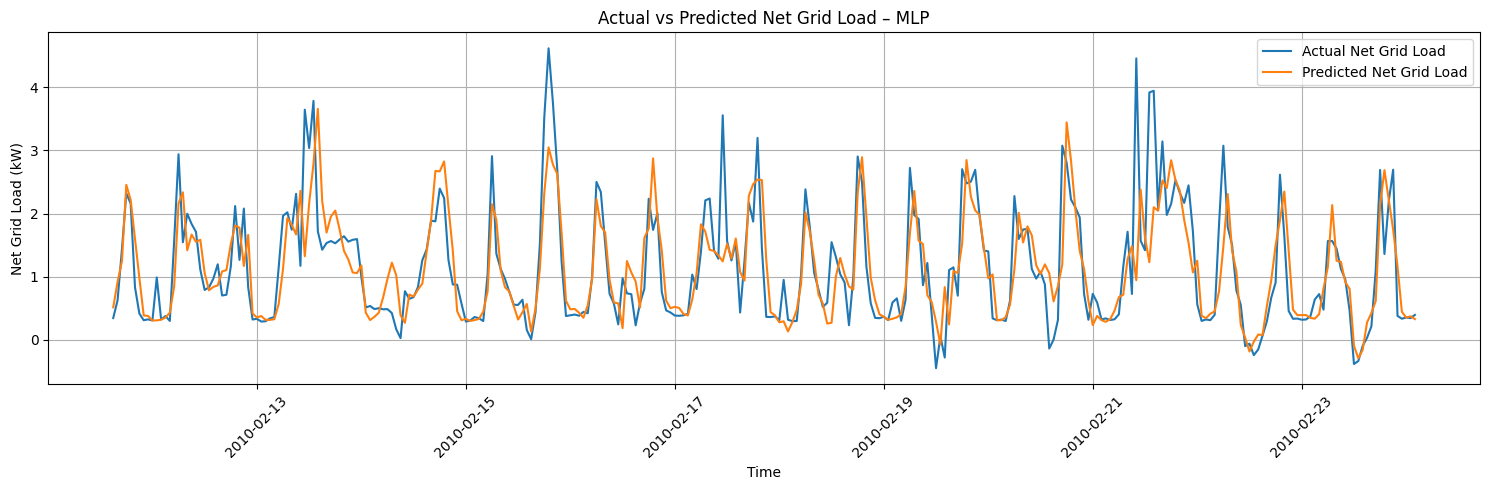

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    y_test.index[:300],
    y_test.iloc[:300],
    label="Actual Net Grid Load"
)

plt.plot(
    y_test.index[:300],
    best_predictions[:300],
    label="Predicted Net Grid Load"
)

plt.title("Actual vs Predicted Net Grid Load – MLP")
plt.xlabel("Time")
plt.ylabel("Net Grid Load (kW)")
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

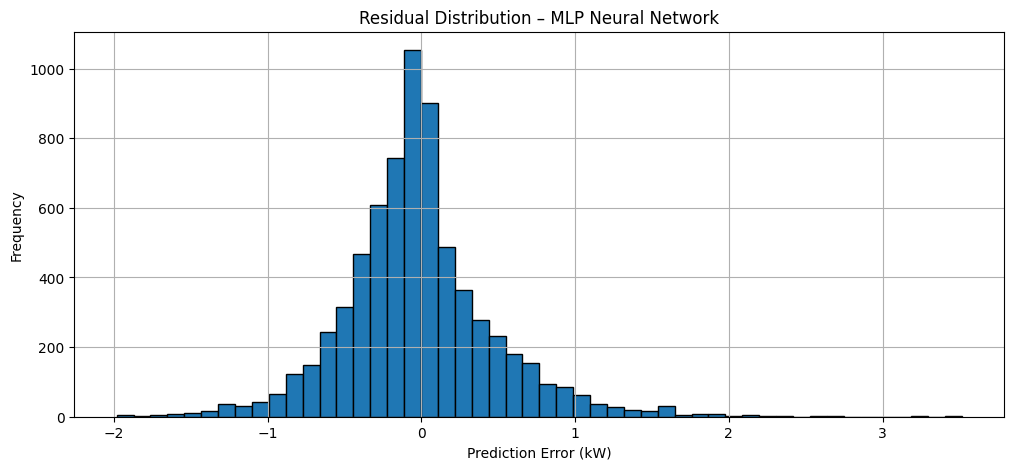

In [ ]:
residuals = y_test.values - best_predictions

plt.figure(figsize=(12, 5))

plt.hist(residuals, bins=50, edgecolor="black")

plt.title("Residual Distribution – MLP Neural Network")
plt.xlabel("Prediction Error (kW)")
plt.ylabel("Frequency")
plt.grid()
plt.show()

In [ ]:
predictions_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": best_predictions,
    "Residual": residuals
}, index=y_test.index)

display(predictions_df.head(10))

,Actual,Predicted,Residual
2010-02-11 15:00:00,0.343141,0.512950,-0.169809
2010-02-11 16:00:00,0.625315,0.916072,-0.290757
2010-02-11 17:00:00,1.436367,1.246184,0.190183
2010-02-11 18:00:00,2.319900,2.454385,-0.134485
2010-02-11 19:00:00,2.159933,2.215593,-0.055659
2010-02-11 20:00:00,0.829867,1.590681,-0.760814
2010-02-11 21:00:00,0.414267,0.980838,-0.566571
2010-02-11 22:00:00,0.307900,0.385240,-0.077340
2010-02-11 23:00:00,0.321600,0.375962,-0.054362
2010-02-12 00:00:00,0.304100,0.303980,0.000120


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
import numpy as np

# Split training data chronologically
cal_split = int(len(X_train) * 0.8)

X_fit = X_train.iloc[:cal_split]
X_cal = X_train.iloc[cal_split:]

y_fit = y_train.iloc[:cal_split]
y_cal = y_train.iloc[cal_split:]

# Scale using only model-fitting data
uncertainty_scaler = StandardScaler()

X_fit_scaled = uncertainty_scaler.fit_transform(X_fit)
X_cal_scaled = uncertainty_scaler.transform(X_cal)
X_test_unc_scaled = uncertainty_scaler.transform(X_test)

print("Model fitting samples:", len(X_fit))
print("Calibration samples:", len(X_cal))
print("Test samples:", len(X_test))

Model fitting samples: 22136
Calibration samples: 5534
Test samples: 6918


In [ ]:
uncertainty_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=200,
    early_stopping=True,
    random_state=42
)

uncertainty_model.fit(X_fit_scaled, y_fit)

print("Calibration model trained successfully!")

Calibration model trained successfully!


In [ ]:
# Predictions on calibration data
cal_predictions = uncertainty_model.predict(X_cal_scaled)

# Absolute calibration errors
cal_errors = np.abs(y_cal.values - cal_predictions)

# 90% conformal interval threshold
n = len(cal_errors)
alpha = 0.10

q_level = min(
    1.0,
    np.ceil((n + 1) * (1 - alpha)) / n
)

interval_width = np.quantile(cal_errors, q_level)

print("90% interval error threshold:", interval_width)

90% interval error threshold: 0.8296612007789642


In [ ]:
# Test predictions from calibrated model
calibrated_predictions = uncertainty_model.predict(
    X_test_unc_scaled
)

lower_bound = calibrated_predictions - interval_width
upper_bound = calibrated_predictions + interval_width

uncertainty_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": calibrated_predictions,
    "Lower_Bound": lower_bound,
    "Upper_Bound": upper_bound
}, index=y_test.index)

display(uncertainty_results.head(10))

,Actual,Predicted,Lower_Bound,Upper_Bound
2010-02-11 15:00:00,0.343141,0.478358,-0.351303,1.308019
2010-02-11 16:00:00,0.625315,0.811478,-0.018184,1.641139
2010-02-11 17:00:00,1.436367,1.172213,0.342552,2.001874
2010-02-11 18:00:00,2.319900,2.421643,1.591982,3.251304
2010-02-11 19:00:00,2.159933,1.973541,1.143879,2.803202
2010-02-11 20:00:00,0.829867,1.160282,0.330621,1.989943
2010-02-11 21:00:00,0.414267,1.003498,0.173837,1.833159
2010-02-11 22:00:00,0.307900,0.630882,-0.198779,1.460543
2010-02-11 23:00:00,0.321600,0.471567,-0.358094,1.301228
2010-02-12 00:00:00,0.304100,0.478820,-0.350842,1.308481


In [ ]:
coverage = np.mean(
    (y_test.values >= lower_bound) &
    (y_test.values <= upper_bound)
) * 100

print(f"Empirical 90% interval coverage: {coverage:.2f}%")

Empirical 90% interval coverage: 90.56%


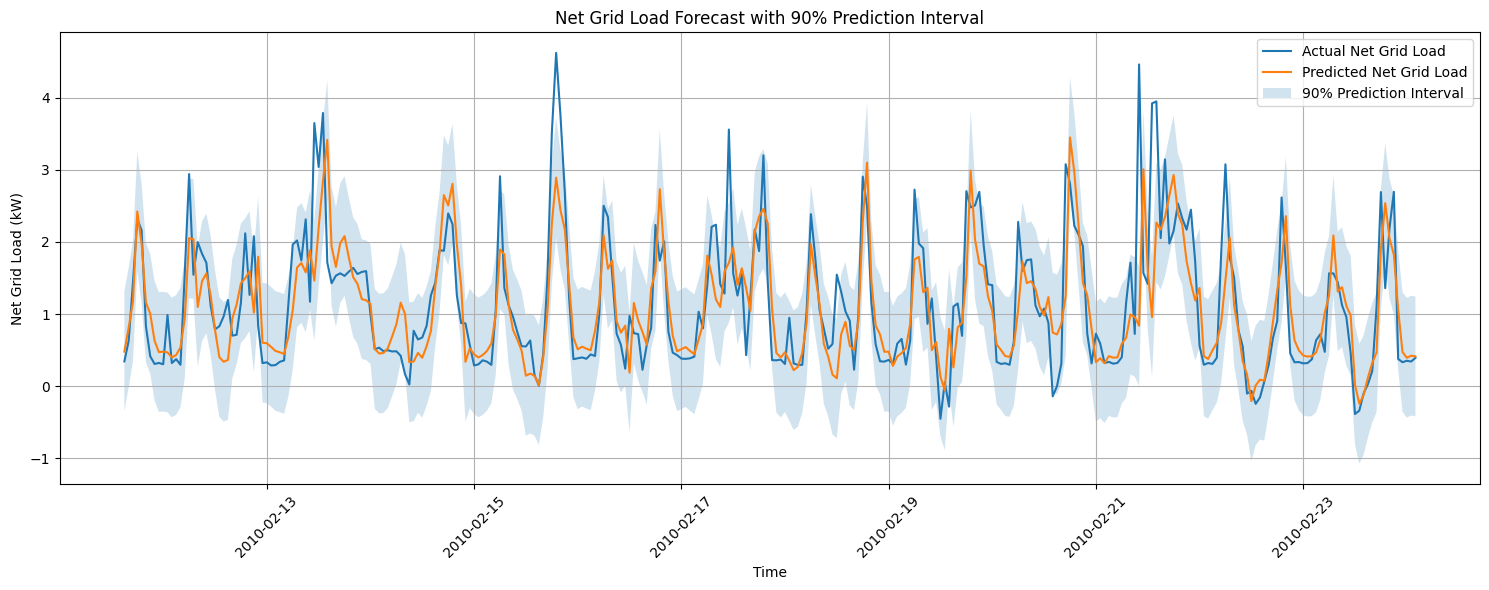

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    uncertainty_results.index[:300],
    uncertainty_results["Actual"].iloc[:300],
    label="Actual Net Grid Load"
)

plt.plot(
    uncertainty_results.index[:300],
    uncertainty_results["Predicted"].iloc[:300],
    label="Predicted Net Grid Load"
)

plt.fill_between(
    uncertainty_results.index[:300],
    uncertainty_results["Lower_Bound"].iloc[:300],
    uncertainty_results["Upper_Bound"].iloc[:300],
    alpha=0.2,
    label="90% Prediction Interval"
)

plt.title("Net Grid Load Forecast with 90% Prediction Interval")
plt.xlabel("Time")
plt.ylabel("Net Grid Load (kW)")
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
average_width = np.mean(
    uncertainty_results["Upper_Bound"] -
    uncertainty_results["Lower_Bound"]
)

print("Empirical Coverage:", round(coverage, 2), "%")
print("Average Interval Width:", round(average_width, 4), "kW")

Empirical Coverage: 90.56 %
Average Interval Width: 1.6593 kW


In [ ]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    uncertainty_model,
    X_test_unc_scaled,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

,Feature,Importance
7,Solar_Generation_kWh,0.361761
3,Global_intensity,0.324207
6,Sub_metering_3,0.232745
0,Global_active_power,0.224300
9,Hour_Sin,0.106156
10,Hour_Cos,0.088990
4,Sub_metering_1,0.052037
5,Sub_metering_2,0.043400
8,Temperature_C,0.018265
11,Day_Sin,0.014324


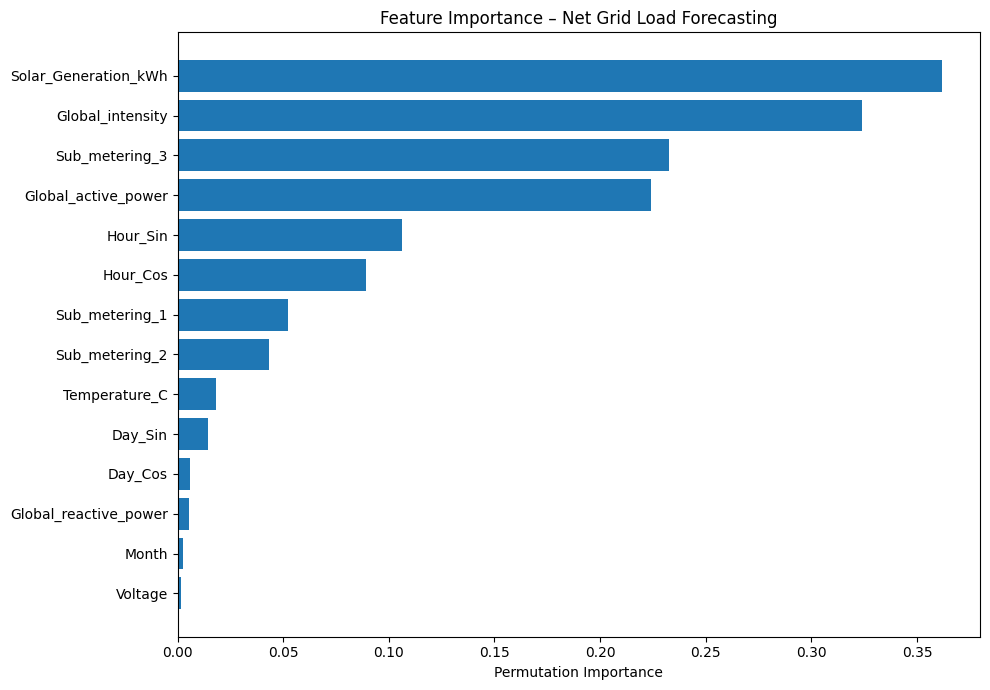

In [ ]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Permutation Importance")
plt.title("Feature Importance – Net Grid Load Forecasting")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Fit scaler only on training data
pca_scaler = StandardScaler()

X_train_pca_scaled = pca_scaler.fit_transform(X_train)
X_test_pca_scaled = pca_scaler.transform(X_test)

# Apply PCA
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_pca_scaled)
X_test_pca = pca.transform(X_test_pca_scaled)

print("Original number of features:", X_train.shape[1])
print("Number of principal components:", pca.n_components_)
print("Explained variance:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


Original number of features: 14
Number of principal components: 11
Explained variance: 97.55 %


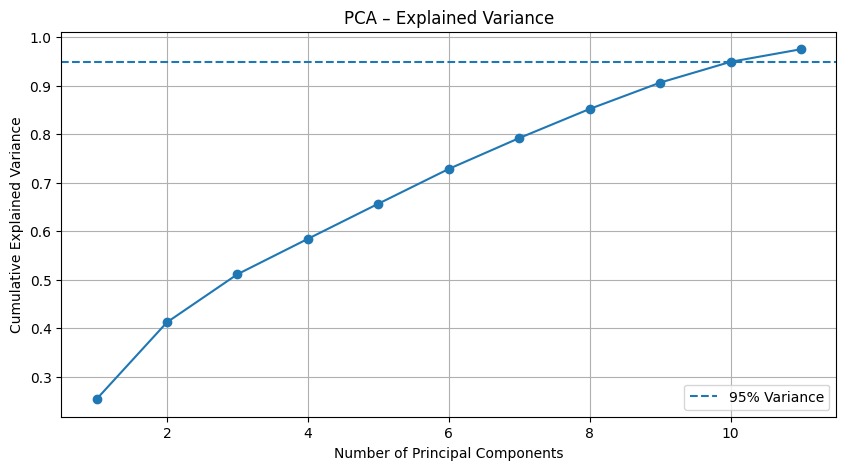

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.95, linestyle="--", label="95% Variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA – Explained Variance")
plt.legend()
plt.grid()
plt.show()

In [ ]:
print("Original training shape:", X_train.shape)
print("PCA training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("PCA testing shape:", X_test_pca.shape)

Original training shape: (27670, 14)
PCA training shape: (27670, 11)
Original testing shape: (6918, 14)
PCA testing shape: (6918, 11)


In [ ]:
print("Original features:", X_train.shape[1])
print("PCA components:", X_train_pca.shape[1])

print("Original training shape:", X_train.shape)
print("PCA training shape:", X_train_pca.shape)

Original features: 14
PCA components: 11
Original training shape: (27670, 14)
PCA training shape: (27670, 11)


In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pca_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=200,
    early_stopping=True,
    random_state=42
)

pca_model.fit(X_train_pca, y_train)

pca_predictions = pca_model.predict(X_test_pca)

pca_mae = mean_absolute_error(y_test, pca_predictions)
pca_rmse = np.sqrt(mean_squared_error(y_test, pca_predictions))
pca_r2 = r2_score(y_test, pca_predictions)

print("PCA Model Results")
print("MAE:", round(pca_mae, 4))
print("RMSE:", round(pca_rmse, 4))
print("R2 Score:", round(pca_r2, 4))

PCA Model Results
MAE: 0.3536
RMSE: 0.4954
R2 Score: 0.6893
